## Dialogue act analysis

Dialogue acts represent the intention of an utterance in a conversation, such as asking a question, giving an answer, making a statement or expressing an opinion. By tagging each turn of a conversation with a dialogue act, we can analyse how the agent and the user interact: does the agent answer questions, does it ask questions itself, does the user give positive or negative answers, does the conversation get stuck in back-channeling or nonsense?

In this notebook, we tag every turn of an EMISSOR scenario with the MIDAS dialogue act tagger. MIDAS is a dialogue act annotation scheme for open domain human-machine spoken conversations with 23 dialogue acts:

```Yu, Dian, and Zhou Yu. "MIDAS: A Dialog Act Annotation Scheme for Open Domain HumanMachine Spoken Conversations." Proceedings of the 16th Conference of the European Chapter of the Association for Computational Linguistics: Main Volume. 2021.```

We use the multilingual XLM-RoBERTa model [CLTL/midas-da-xlmroberta](https://huggingface.co/CLTL/midas-da-xlmroberta) that was finetuned on the MIDAS data. It classifies an utterance given the previous utterance, so that, for example, "Yes" can be recognised as a positive answer to a question. Since it is multilingual, it also works for other languages such as Dutch.

The ```MidasDialogTagger``` class in ```midas_classifier.py``` wraps the model.

## Prerequisites

This notebook relies on the transformers package and the EMISSOR package for loading the EMISSOR scenarios. We also need ```pandas```, ```matplotlib``` and ```seaborn``` for the results. These packages can be installed through ```pip```:

In [ ]:
# !pip install emissor
# !pip install torch
# !pip install transformers
# !pip install pandas
# !pip install matplotlib
# !pip install seaborn

## Loading the MIDAS dialogue act tagger

The model is downloaded from huggingface the first time. You can also download it and pass the path to your local copy.

Note that the model is an XLM-RoBERTa model, but its configuration does not tell this to ```AutoTokenizer```. The ```MidasDialogTagger``` therefore loads the XLM-RoBERTa tokenizer explicitly. Loading the model with the default tokenizer splits the text into single characters and gives meaningless dialogue acts.

In [1]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl.emissor_evaluation
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from src.cltl.emissor_evaluation.dialogue_act.midas_classifier import MidasDialogTagger, get_dialogue_act_score

model_path = "CLTL/midas-da-xlmroberta"
# Path to your local copy of the model
#model_path = "../../models/midas-da-xlmroberta"
tagger = MidasDialogTagger(model_path=model_path)

Loading MIDAS model... CLTL/midas-da-xlmroberta


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

We first test the tagger on a short conversation. Each utterance is classified given the previous one:

In [3]:
tagger.reset()
for utterance in ["I love cats", "Do you love cats?", "Yes, I do", "Ik ben dol op katten", "Hou jij van katten?", "Nee, honden"]:
    dialogue_act = tagger.extract_dialogue_act(utterance)[0]
    print(f"{utterance:25s} {dialogue_act.value:25s} {dialogue_act.confidence:.2f}")

[[{'label': 'opinion', 'score': 0.45253247022628784}]]
I love cats               opinion                   0.45
[[{'label': 'yes_no_question', 'score': 0.8798638582229614}]]
Do you love cats?         yes_no_question           0.88
[[{'label': 'pos_answer', 'score': 0.8204182386398315}]]
Yes, I do                 pos_answer                0.82
[[{'label': 'statement', 'score': 0.8670987486839294}]]
Ik ben dol op katten      statement                 0.87
[[{'label': 'yes_no_question', 'score': 0.6966983079910278}]]
Hou jij van katten?       yes_no_question           0.70
[[{'label': 'neg_answer', 'score': 0.7956945300102234}]]
Nee, honden               neg_answer                0.80


## Obtaining the conversations from EMISSOR

The next functions get the text signals from the conversations captured in the EMISSOR scenarios and tag each turn with a dialogue act. Set ```SCENARIOS``` to the list of scenarios to process. With ```get_scenario_ids(EMISSOR)``` all subfolders of ```EMISSOR``` that contain a scenario JSON file are processed.

Each dialogue act also gets a score from -5 to +5 in ```da_score```, which tells how positive the dialogue act is for the conversation. The scores come from the scales ```DIALOGUE_ACT_NEG_SCALE```, ```DIALOGUE_ACT_NEUTRAL_SCALE``` and ```DIALOGUE_ACT_POS_SCALE``` in ```midas_classifier.py```. The dialogue acts on the negative scale are spread from -5 (the first in the list) to -1 (the last), the neutral dialogue acts get 0 and the dialogue acts on the positive scale are spread from +1 (the first) to +5 (the last). Change the order of the lists to change the scores.

In [4]:
import os
import pandas as pd
from src.cltl.emissor_evaluation.emissor import emissor_util as util

In [5]:
from src.cltl.emissor_evaluation.dialogue_act.midas_classifier import DIALOGUE_ACT_SCORES

pd.Series(DIALOGUE_ACT_SCORES, name="da_score").sort_values()

abandon                 -5
complaint               -4
nonsense                -4
neg_answer              -3
apology                 -3
respond_to_apology      -2
comment                 -2
opinion                 -1
closing                  0
hold                     0
opening                  0
other                    0
dev_command              0
other_answers            0
yes_no_question          0
statement                0
command                  0
open_question_opinion    0
back-channeling          1
thanking                 2
open_question_factual    3
pos_answer               4
appreciation             5
Name: da_score, dtype: int64

In [6]:
EMISSOR = "../../../../emissor"
SCENARIO = "2ad0c8b9-4e62-4f11-809c-57bf76487f95"


EMISSOR="/Users/piek/Desktop/Leolani/cltl-apps/cltl-apps-restructure_f_server/storage/emissor"
SCENARIO="5a55e02f-e2be-4dce-a9b6-bb3c6dba1480"

def get_scenario_ids(emissor_folder):
    scenario_ids = []
    for name in sorted(os.listdir(emissor_folder)):
        scenario_folder = os.path.join(emissor_folder, name)
        if os.path.isdir(scenario_folder) and os.path.exists(os.path.join(scenario_folder, name + ".json")):
            scenario_ids.append(name)
    return scenario_ids

def dialogue_acts_for_scenario(emissor_folder, scenario_id, tagger):
    text_signals = util.get_text_signals_from_a_scenario(emissor_folder, scenario_id)
    print('There are:', len(text_signals), 'turns in this scenario:', scenario_id)
    # every conversation starts without a previous utterance
    tagger.reset()
    da_results = []
    for index, text_signal in enumerate(text_signals):
        speaker = util.get_speaker_from_text_signal(text_signal)
        text = text_signal.text
        dialogue_acts = tagger.extract_dialogue_act(text)
        dialogue_act = dialogue_acts[0].value if dialogue_acts else None
        confidence = dialogue_acts[0].confidence if dialogue_acts else None
        row = {"Scenario": scenario_id, "Turn": text_signal.id, "Speaker": speaker, "Response": text,
               "dialogue_act": dialogue_act, "da_confidence": confidence,
               "da_score": get_dialogue_act_score(dialogue_act)}
        da_results.append(row)
    return da_results

SCENARIOS = [SCENARIO]
# To process all scenarios in the EMISSOR folder:
#SCENARIOS = get_scenario_ids(EMISSOR)
print('Processing', len(SCENARIOS), 'scenarios')

Processing 1 scenarios


In [7]:
all_da_results = []
for SCENARIO in SCENARIOS:
    try:
        da_results = dialogue_acts_for_scenario(EMISSOR, SCENARIO, tagger)
    except Exception as e:
        print('Skipping scenario', SCENARIO, 'because of error:', e)
        continue
    if not da_results:
        continue
    all_da_results.extend(da_results)

    df = pd.DataFrame(da_results)
    evaluation_folder = os.path.join(EMISSOR, SCENARIO, 'evaluation')
    os.makedirs(evaluation_folder, exist_ok=True)
    file_name = SCENARIO+"_dialogue_act_evaluation.csv"
    df.to_csv(os.path.join(evaluation_folder, file_name), sep=";", index=False)

all_df = pd.DataFrame(all_da_results)
if len(SCENARIOS) > 1:
    all_df.to_csv(os.path.join(EMISSOR, "all_scenarios_dialogue_act_evaluation.csv"), sep=";", index=False)
all_df[["Speaker", "Response", "dialogue_act", "da_confidence", "da_score"]].head(20)

There are: 46 turns in this scenario: 5a55e02f-e2be-4dce-a9b6-bb3c6dba1480
[[{'label': 'command', 'score': 0.3745484948158264}]]
[[{'label': 'command', 'score': 0.5329340100288391}]]
[[{'label': 'abandon', 'score': 0.7029951214790344}]]
[[{'label': 'open_question_factual', 'score': 0.2483065277338028}]]
[[{'label': 'statement', 'score': 0.6411774754524231}]]
[[{'label': 'statement', 'score': 0.38845765590667725}]]
[[{'label': 'open_question_factual', 'score': 0.8511402606964111}]]
[[{'label': 'statement', 'score': 0.8998739719390869}]]
[[{'label': 'open_question_opinion', 'score': 0.44219815731048584}]]
[[{'label': 'opinion', 'score': 0.16359643638134003}]]
[[{'label': 'open_question_factual', 'score': 0.7114795446395874}]]
[[{'label': 'open_question_factual', 'score': 0.5777468681335449}]]
[[{'label': 'statement', 'score': 0.944807767868042}]]
[[{'label': 'open_question_factual', 'score': 0.8512334823608398}]]
[[{'label': 'statement', 'score': 0.9679421782493591}]]
[[{'label': 'commen

,Speaker,Response,dialogue_act,da_confidence,da_score
0,LEOLANI,What's up? Do you want to talk to me?,command,0.374548,0
1,SPEAKER,yes,command,0.532934,0
2,SPEAKER,look,abandon,0.702995,-5
3,LEOLANI,What’s been going on with your body lately—hav...,open_question_factual,0.248307,3
4,LEOLANI,How has your mood and overall headspace been s...,statement,0.641177,0
5,LEOLANI,How long do you usually stay in a particular m...,statement,0.388458,0
6,LEOLANI,How long do you stay shifted?,open_question_factual,0.851140,3
7,SPEAKER,one day,statement,0.899874,0
8,LEOLANI,That tweak in wording makes sense and keeps th...,open_question_opinion,0.442198,0
9,LEOLANI,"Besides that day at home in Weesp, was there a...",opinion,0.163596,-1


Each conversation is saved to a CSV file ```<scenario>_dialogue_act_evaluation.csv``` in the ```evaluation``` subfolder of its scenario. When more than one scenario is processed, all conversations together are also saved to ```all_scenarios_dialogue_act_evaluation.csv``` in the ```EMISSOR``` folder. The file has the turns on each row with the scenario identifier, the turn identifier, the speaker and the response, and the columns for the dialogue act (```dialogue_act```), the confidence of the model (```da_confidence```) and the score of the dialogue act (```da_score```).

Since the file has the same ```Turn```, ```Speaker``` and ```Response``` columns as the other evaluation files, it can also be plotted with ```metrics_plotting.py``` (metric ```dialogue_act```) and ```plot_interaction.py``` (score ```da_score```, which is also used for the dialogue act file in the stacked plots).

## Comparing the dialogue acts of the agent and the user

Since we tag both the user (SPEAKER) and the agent (LEOLANI), we can compare which dialogue acts each of them uses. The next table counts the dialogue acts per speaker:

In [8]:
da_counts = pd.crosstab(all_df["dialogue_act"], all_df["Speaker"], margins=True, margins_name="total")
da_counts.sort_values("total", ascending=False)

Speaker,LEOLANI,SPEAKER,total
dialogue_act,,,
total,26,20,46
statement,11,16,27
open_question_factual,10,0,10
abandon,0,2,2
command,1,1,2
comment,1,0,1
open_question_opinion,1,0,1
opinion,1,0,1
pos_answer,0,1,1


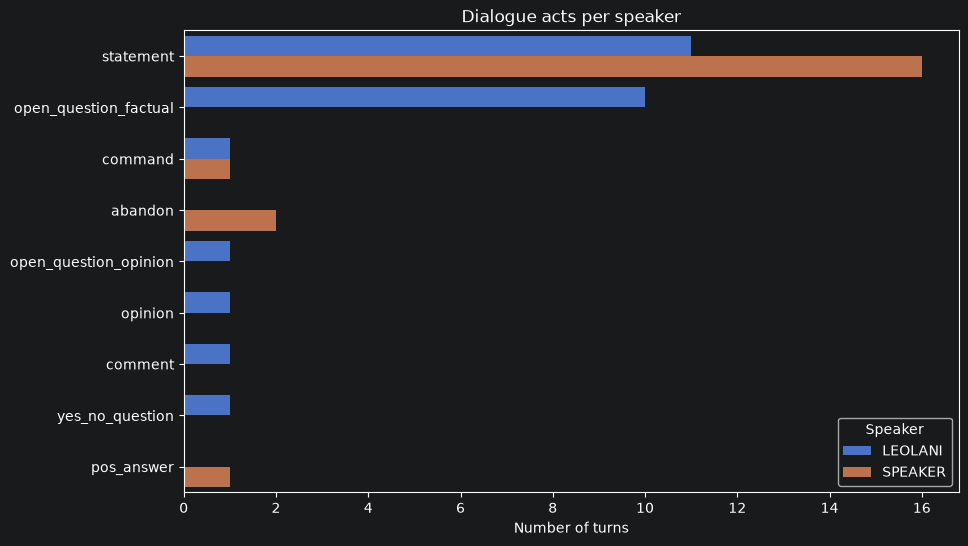

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

order = all_df["dialogue_act"].value_counts().index
plt.figure(figsize=(10, 6))
sns.countplot(data=all_df, y="dialogue_act", hue="Speaker", order=order)
plt.title("Dialogue acts per speaker")
plt.xlabel("Number of turns")
plt.ylabel("")
plt.show()

The confidence of the model tells how certain it is about the dialogue act. A low average confidence for a speaker may indicate utterances that are hard to interpret, such as incomplete or nonsensical utterances:

In [10]:
all_df.groupby("Speaker")["da_confidence"].agg(["mean", "min", "max", "count"])

,mean,min,max,count
Speaker,,,,
LEOLANI,0.554379,0.146285,0.862522,26
SPEAKER,0.846150,0.449337,0.967942,20


## Dialogue act scores over the conversation

The scores of the dialogue acts show whether the conversation goes well: positive dialogue acts such as appreciation and positive answers score above 0 and negative dialogue acts such as complaints and abandoning score below 0. The next table gives the average score per speaker and the plot shows the score of each turn over the conversation.

In [11]:
all_df.groupby("Speaker")["da_score"].agg(["mean", "min", "max", "count"])

,mean,min,max,count
Speaker,,,,
LEOLANI,1.038462,-2,3,26
SPEAKER,-0.300000,-5,4,20


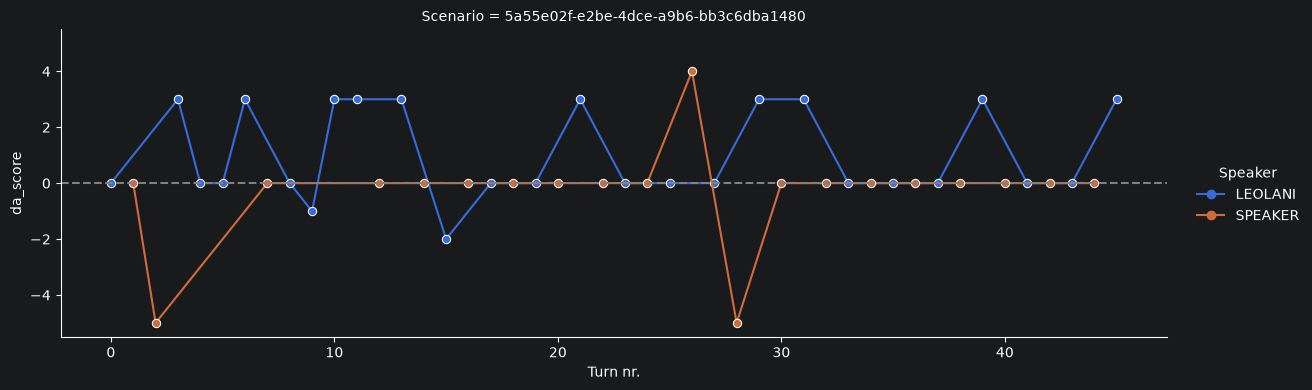

In [12]:
all_df["Turn nr."] = all_df.groupby("Scenario").cumcount()
g = sns.relplot(data=all_df, x="Turn nr.", y="da_score", hue="Speaker", col="Scenario", col_wrap=1,
                kind="line", marker="o", height=4, aspect=3)
g.set(ylim=(-5.5, 5.5))
g.refline(y=0, color="grey", linestyle="--")
plt.show()

## Dialogue act transitions

The dialogue act of a response only makes sense in relation to the previous turn. The next table counts how often a dialogue act (rows) is followed by another dialogue act (columns) in the next turn, e.g. how often a ```yes_no_question``` is followed by a ```pos_answer``` or ```neg_answer```. Turns are only paired within the same scenario.

In [13]:
all_df["previous_dialogue_act"] = all_df.groupby("Scenario")["dialogue_act"].shift(1)
transitions = pd.crosstab(all_df["previous_dialogue_act"], all_df["dialogue_act"])
transitions

dialogue_act,abandon,command,comment,open_question_factual,open_question_opinion,opinion,pos_answer,statement,yes_no_question
previous_dialogue_act,,,,,,,,,
abandon,0,0,0,2,0,0,0,0,0
command,1,1,0,0,0,0,0,0,0
comment,0,0,0,0,0,0,0,1,0
open_question_factual,0,0,0,1,0,0,0,8,0
open_question_opinion,0,0,0,0,0,1,0,0,0
opinion,0,0,0,1,0,0,0,0,0
pos_answer,0,0,0,0,0,0,0,1,0
statement,1,0,1,6,1,0,0,17,1
yes_no_question,0,0,0,0,0,0,1,0,0


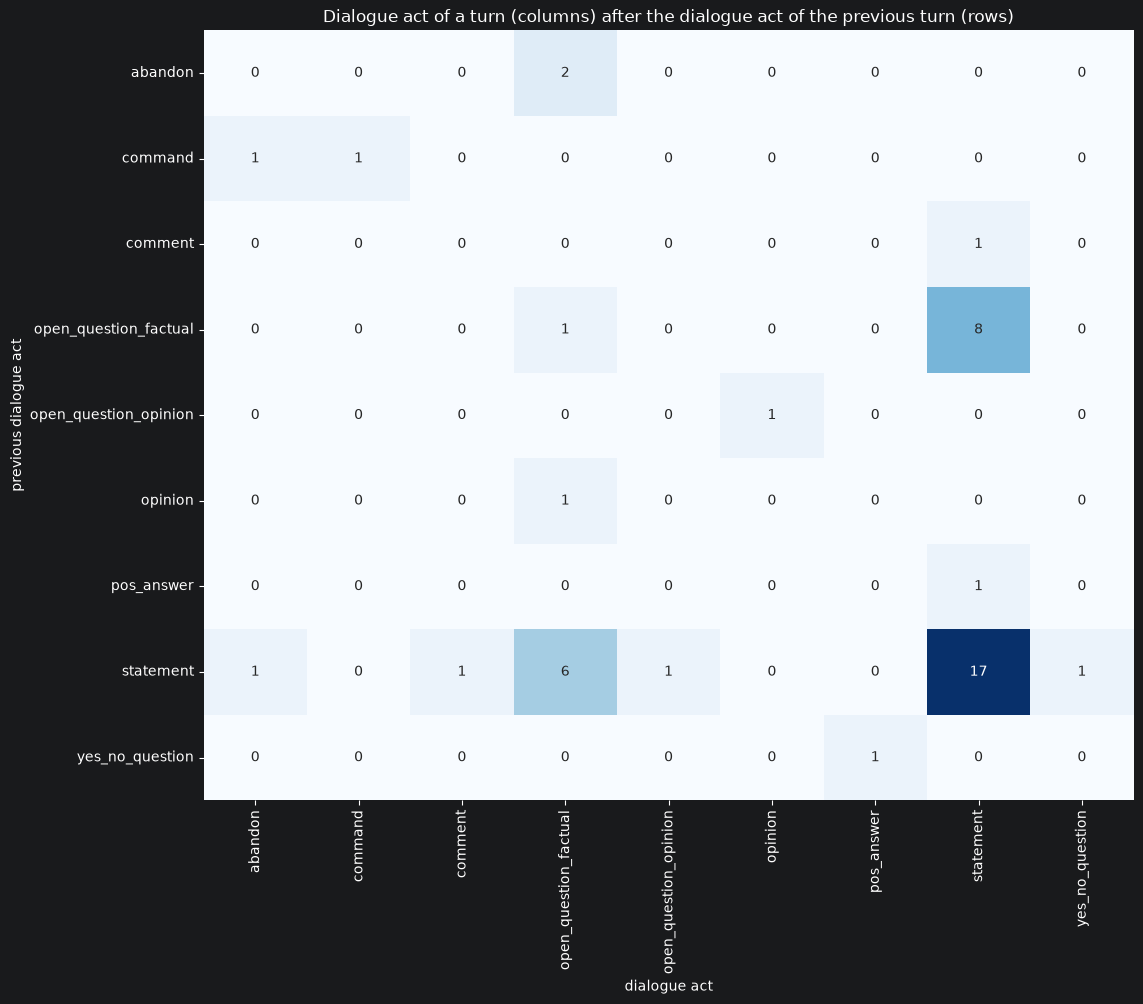

In [14]:
plt.figure(figsize=(12, 10))
sns.heatmap(transitions, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Dialogue act of a turn (columns) after the dialogue act of the previous turn (rows)")
plt.xlabel("dialogue act")
plt.ylabel("previous dialogue act")
plt.show()

Look at the questions in the rows: are they followed by answers? And what does the agent do after a statement or opinion of the user? What does that tell you about the conversation?

## End of notebook